# EGF-TNFα signaling

This notebook reproduces the analysis of the EGF-TNFα signaling model of the [MaBoSS website](https://maboss.curie.fr).

This model was used as an example for the SBML-qual standard format
([Chaouiya et al., 2013](https://doi.org/10.1186/1752-0509-7-135)), and can be found in the
[BioModels](https://www.ebi.ac.uk/biomodels/BIOMD0000000562) database (BIOMD0000000562). The MaBoSS files
were exported from [GINsim](http://ginsim.org), with `egf` and `tnfa` as inputs.

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/), and the files `chaouiya_maboss.bnd` and
`chaouiya_maboss.cfg`, in the same folder as this notebook.

In [1]:
import os
import maboss
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# Common style for the figures of the MaBoSS website notebooks
COLORS = ["#FF7F00", "#1F77B4", "#2CA02C", "#D62728", "#9467BD",
          "#8C564B", "#E377C2", "#17BECF", "#BCBD22", "#7F7F7F"]
mpl.rcParams.update({
    "figure.figsize": (7, 4),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "axes.prop_cycle": mpl.cycler(color=COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "legend.frameon": False,
    "lines.linewidth": 2,
})

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    """Save a figure in the figures folder."""
    fig.savefig(os.path.join(FIG_DIR, name + ".png"))

def state_label(state):
    """Readable label for a MaBoSS state."""
    return "none active" if state == "<nil>" else state.replace(" -- ", ", ")

def pie(probas, ax, title=None, min_proba=0.01, labels=None):
    """Pie chart of a distribution; probabilities below min_proba are grouped as 'others'."""
    probas = pd.Series(probas).sort_values(ascending=False)
    small = probas[probas < min_proba]
    probas = probas[probas >= min_proba]
    if len(small) > 0:
        probas["others"] = small.sum()
    names = [labels.get(s, state_label(s)) if labels else state_label(s) for s in probas.index]
    colors = [COLORS[i % len(COLORS)] if s != "others" else "#D9D9D9" for i, s in enumerate(probas.index)]
    wedges, _ = ax.pie(probas.values, colors=colors, startangle=90, counterclock=False,
                       wedgeprops={"linewidth": 1, "edgecolor": "white"})
    ax.legend(wedges, [f"{n} ({p:.1%})" for n, p in zip(names, probas.values)],
              loc="center left", bbox_to_anchor=(1, 0.5))
    ax.set_aspect("equal")
    if title:
        ax.set_title(title)

def set_refstate_all(sim, value=0):
    """Give a reference state to every node.

    With MaBoSS 2.6.6, the states of the stationary distributions only include the nodes
    having a reference state; this makes them include all the nodes, as in previous versions.
    """
    for node in sim.network:
        if node not in sim.refstate:
            sim.refstate[node] = value

ipylab module is not installed, menus and toolbar are disabled.


## Simulation

In the configuration file, the initial state of every node is random, and `ras`, `egf` and `akt` are the
output nodes. We set the following conditions:

* no TNFα (`tnfa` is initially inactive), EGF being present in half of the cells;
* `erk` is also an output node, to follow its activity;
* the simulation runs until time 50.

In [2]:
sim = maboss.load("chaouiya_maboss.bnd", "chaouiya_maboss.cfg")
sim.network.set_istate("tnfa", [1, 0])
sim.network["erk"].is_internal = False
sim.update_parameters(max_time=50, time_tick=0.1)
result = sim.run()

## Fixed points

The simulation reaches three fixed points. They correspond to the stable states of the published model
for the wild type: with EGF, AKT is active, while without EGF, GSK3 is active (with or without PH).

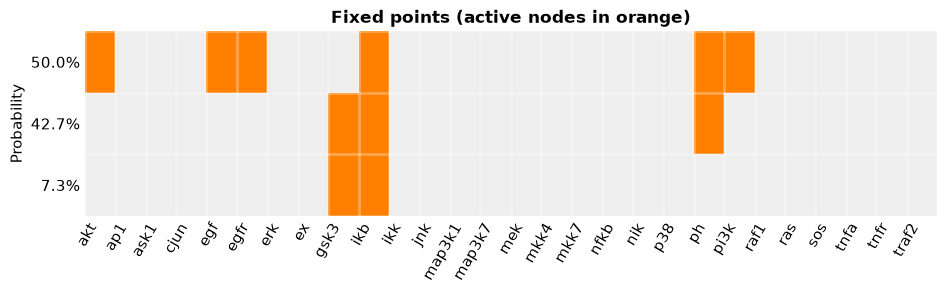

In [3]:
fixed_points = result.get_fptable().sort_values("Proba", ascending=False).reset_index(drop=True)
nodes = sorted(fixed_points.columns[3:], key=str.lower)

fig, ax = plt.subplots(figsize=(11, 2.4))
ax.imshow(fixed_points[nodes].values, cmap=mpl.colors.ListedColormap(["#EEEEEE", COLORS[0]]),
          vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(nodes)), nodes, rotation=60, ha="right")
ax.set_yticks(range(len(fixed_points)), [f"{p:.1%}" for p in fixed_points["Proba"]])
ax.set_xticks(np.arange(-0.5, len(nodes)), minor=True)
ax.set_yticks(np.arange(-0.5, len(fixed_points)), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.grid(which="major", visible=False)
ax.tick_params(which="both", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_ylabel("Probability")
ax.set_title("Fixed points (active nodes in orange)")
save(fig, "egf_tnf_fixed_points")

## Trajectories

The activities of ERK and RAS are transient, while AKT remains active when EGF is present.

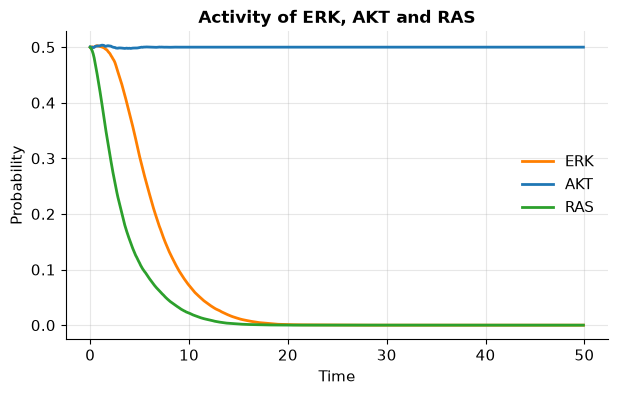

In [4]:
trajectories = result.get_nodes_probtraj()

fig, ax = plt.subplots()
for node in ["erk", "akt", "ras"]:
    ax.plot(trajectories.index, trajectories[node], label=node.upper())
ax.set_xlabel("Time")
ax.set_ylabel("Probability")
ax.set_title("Activity of ERK, AKT and RAS")
ax.legend()
save(fig, "egf_tnf_trajectories")